# IMPORT

In [72]:
%load_ext autoreload
%autoreload 2

from dataset import read_image, make_loaders, SquarePad, build_cache
from train import validate, fit, run_experiment

import timm
import pandas as pd
from PIL import Image
from pathlib import Path
import hashlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import optuna
from optuna.visualization.matplotlib import plot_param_importances
import gc

from sklearn.model_selection import train_test_split

import albumentations as A
import albumentations.core.transforms_interface as ti
from torch.utils.data import TensorDataset

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# LOAD DATA AND PREPROCESSING

Download the [Zindi gesture data](https://disk.360.yandex.ru/d/N_DIJPiWP2wBTw)

In [2]:
images_dir = Path("./data/Images")

In [3]:
df = pd.read_csv("./data/Train.csv")

In [4]:
df.head()

,img_IDS,Label
0,ImageID_33HMDMJ3,Temple
1,ImageID_V5POEX4O,Church
2,ImageID_89CCCCW6,Enough/Satisfied
3,ImageID_GNJXOWX5,Me
4,ImageID_7Q9LOP7R,Love


In [5]:
df["Label"].value_counts()

Label
Enough/Satisfied    695
Mosque              695
Seat                695
Temple              694
Church              694
Me                  694
Love                694
You                 694
Friend              694
Name: count, dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6249 entries, 0 to 6248
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   img_IDS  6249 non-null   str  
 1   Label    6249 non-null   str  
dtypes: str(2)
memory usage: 97.8 KB


In [7]:
df["img_IDS"].duplicated(keep=False).sum()

np.int64(0)

In [8]:
classes = df["Label"].unique().tolist()

label_to_idx = {label: idx for idx, label in enumerate(classes)}

df["Label_idx"] = df["Label"].map(label_to_idx)

label_to_idx

{'Temple': 0,
 'Church': 1,
 'Enough/Satisfied': 2,
 'Me': 3,
 'Love': 4,
 'Mosque': 5,
 'You': 6,
 'Friend': 7,
 'Seat': 8}

In [9]:
df

,img_IDS,Label,Label_idx
0,ImageID_33HMDMJ3,Temple,0
1,ImageID_V5POEX4O,Church,1
2,ImageID_89CCCCW6,Enough/Satisfied,2
3,ImageID_GNJXOWX5,Me,3
4,ImageID_7Q9LOP7R,Love,4
...,...,...,...
6244,ImageID_F2HTAA5P,Love,4
6245,ImageID_0D69ZQ4X,Church,1
6246,ImageID_E67IZXVJ,Seat,8
6247,ImageID_ENGL8NP3,You,6


### Check image sizes

In [10]:
sizes = {}

for path in images_dir.glob("*.jpg"):
    with Image.open(path) as img:
        sizes[img.size] = sizes.get(img.size, 0) + 1

sizes

{(720, 1280): 7112, (1280, 720): 1816}

### Check for exact duplicate images (by file hash)

In [11]:
hashes = {}

for path in images_dir.glob("*.jpg"):
    with open(path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    hashes.setdefault(file_hash, []).append(path)

duplicates = {file_hash: paths for file_hash, paths in hashes.items() if len(paths) > 1}

print(f"Всего изображений: {len(list(images_dir.glob('*.jpg')))}")
print(f"Групп дубликатов: {len(duplicates)}")

Всего изображений: 8928
Групп дубликатов: 0


### Examples of data

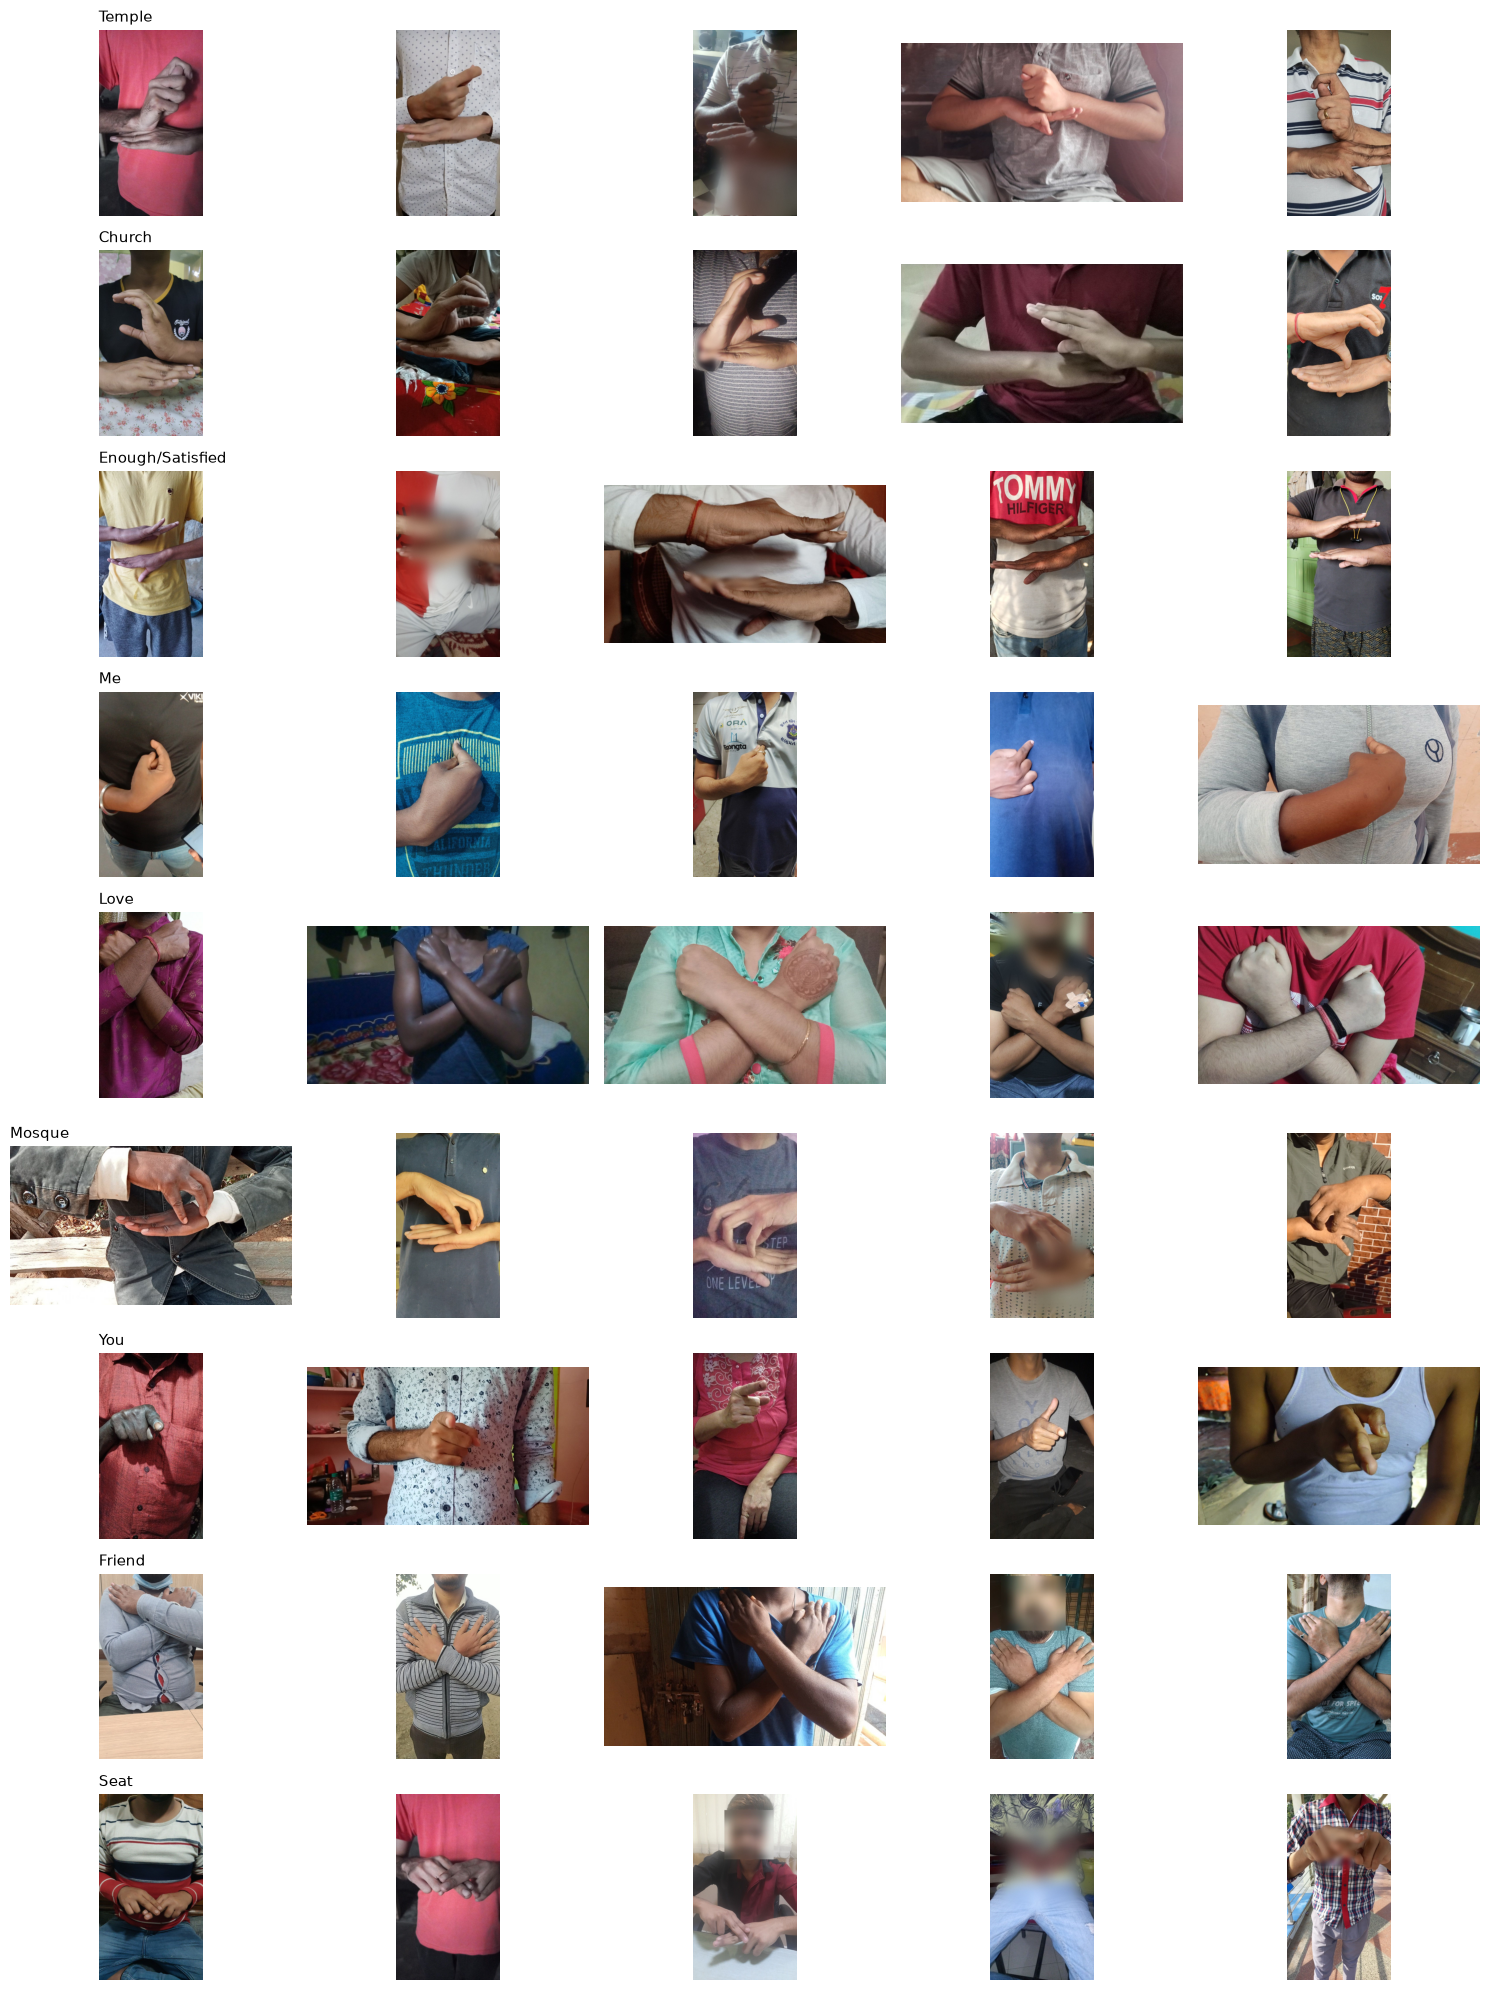

In [12]:
classes = df["Label"].unique()

fig, axes = plt.subplots(nrows=len(classes), ncols=5, figsize=(15, 20))

for row, label in enumerate(classes):
    samples = df[df["Label"] == label].sample(5, random_state=21)

    for col, (_, sample) in enumerate(samples.iterrows()):
        image_path = images_dir / f"{sample['img_IDS']}.jpg"

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

    axes[row, 0].set_title(label, fontsize=11, loc="left")

plt.tight_layout()
plt.show()

### Split data

In [13]:
train, valid = train_test_split(
    df, test_size=0.33, random_state=21, stratify=df["Label"]
)

print(f"Train: {len(train)}")
print(f"Valid: {len(valid)}")
print()
print("Train distribution:")
print(train["Label"].value_counts(normalize=True))

print("\nValidation distribution:")
print(valid["Label"].value_counts(normalize=True))

Train: 4186
Valid: 2063

Train distribution:
Label
Seat                0.111323
Enough/Satisfied    0.111085
Temple              0.111085
Love                0.111085
Friend              0.111085
Church              0.111085
Mosque              0.111085
Me                  0.111085
You                 0.111085
Name: proportion, dtype: float64

Validation distribution:
Label
Mosque              0.111488
Enough/Satisfied    0.111488
Me                  0.111003
Temple              0.111003
Seat                0.111003
Friend              0.111003
You                 0.111003
Church              0.111003
Love                0.111003
Name: proportion, dtype: float64


### Create dataset and dataloader

#### Image Resizing Methods

| Method | What it does | Pros | Cons |
|---|---|---|---|
| **Direct Resize** | Resizes the image directly to `N × N` | Simple, fast, keeps the entire image | Distorts the aspect ratio |
| **Crop + Resize** | Preserves the aspect ratio, crops the image to a square, then resizes it to `N × N` | No geometric distortion | Removes part of the image and may lose important information |
| **Padding + Resize** | Preserves the aspect ratio, adds padding to make the image square, then resizes it to `N × N` | No distortion, keeps the entire image | Adds empty areas, so the useful image occupies fewer pixels |

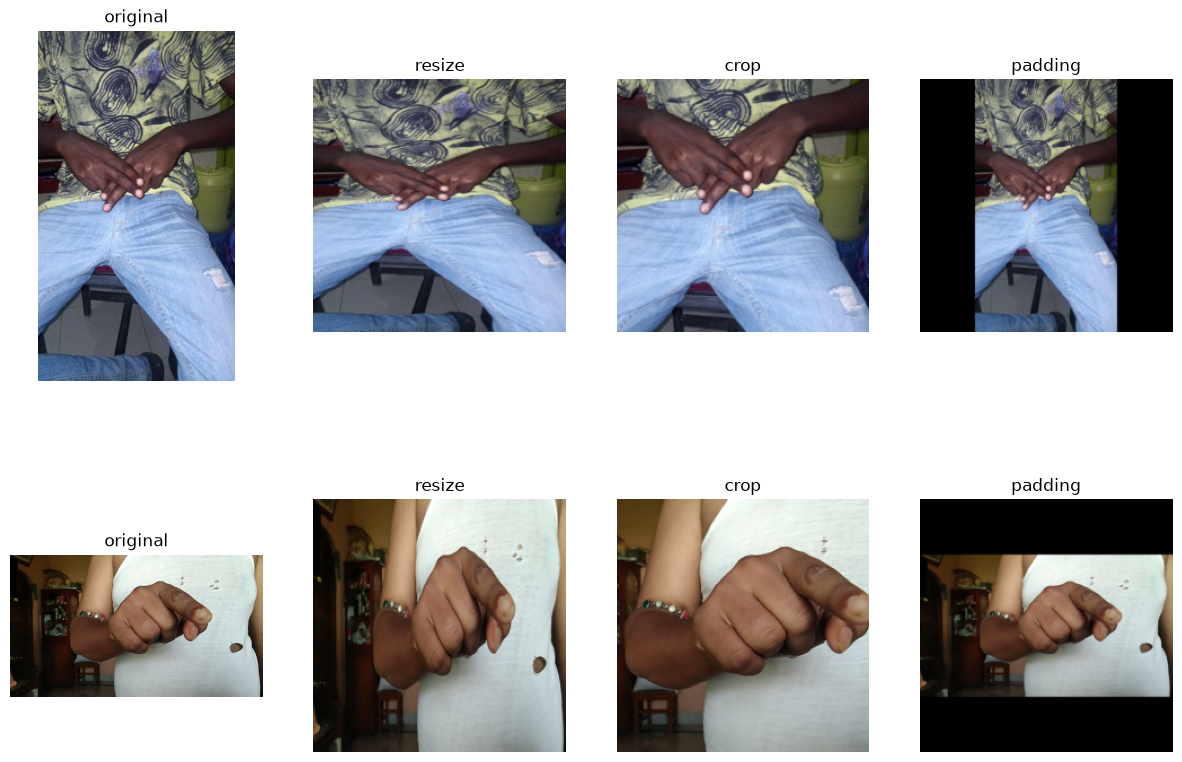

In [14]:
size = (224, 224)

resize = v2.Compose([
    v2.ToImage(),
    v2.Resize(size),
])

crop = v2.Compose([
    v2.ToImage(),
    v2.Resize(max(size)),
    v2.CenterCrop(size),
])

padding = v2.Compose([
    v2.ToImage(),
    SquarePad(),
    v2.Resize(size),
])

fig, axes = plt.subplots(2, 4, figsize=(15, 10))

images_ind = [0, 26]  # one for vertical, one for wide

for row, index_of_image in enumerate(images_ind):

    image_path = images_dir / f"{train['img_IDS'].iloc[index_of_image]}.jpg"
    image = read_image(image_path)

    variants = [
        ("original", image),
        ("resize", resize(image)),
        ("crop", crop(image)),
        ("padding", padding(image)),
    ]

    for col, (method, image_tensor) in enumerate(variants):

        if method == "original":
            axes[row, col].imshow(image)
        else:
            axes[row, col].imshow(image_tensor.permute(1, 2, 0))

        axes[row, col].axis("off")
        axes[row, col].set_title(method)

plt.show()

### Build the train and validation DataLoaders

We use TensorDataset because we are running an Optuna optimization. Since our data fits entirely into GPU memory, TensorDataset is much faster than a standard Dataset.

In [15]:
gc.collect()
torch.cuda.empty_cache()

In [16]:
print(f"Активно занято тензорами: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
print(f"Всего зарезервировано PyTorch: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

Активно занято тензорами: 0.00 MB
Всего зарезервировано PyTorch: 0.00 MB


In [17]:
def make_gpu_loaders(
    train: pd.DataFrame,
    valid: pd.DataFrame,
    images_dir: Path,
    device: torch.device,
    size: tuple[int, int] = (224, 224),
    batch_size_train: int = 64,
    batch_size_valid: int = 256,
) -> tuple[DataLoader, DataLoader]:
    X_train, y_train = build_cache(train, images_dir, size=size)
    X_valid, y_valid = build_cache(valid, images_dir, size=size)

    X_train, y_train = X_train.to(device), y_train.to(device)
    X_valid, y_valid = X_valid.to(device), y_valid.to(device)

    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size_train, shuffle=True)
    valid_loader = DataLoader(TensorDataset(X_valid, y_valid), batch_size=batch_size_valid, shuffle=False)

    return train_loader, valid_loader

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

SIZE = (224, 224)

train_loader, valid_loader = make_gpu_loaders(
    train=train,
    valid=valid,
    images_dir=images_dir,
    device=device,
    size=SIZE,
    batch_size_train=64,
    batch_size_valid=256,
)


In [19]:
print(f"Активно занято тензорами: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
print(f"Всего зарезервировано PyTorch: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

Активно занято тензорами: 3588.66 MB
Всего зарезервировано PyTorch: 3592.00 MB


### OPTUNA Hyperparameter optimization

In [20]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "silu": nn.SiLU,
    "gelu": nn.GELU,
}

CHANNELS = {
    "16_32": (16, 32),
    "32_64": (32, 64),
    "16_32_64": (16, 32, 64),
    "32_64_128": (32, 64, 128),
    "16_32_64_128": (16, 32, 64, 128),
    "32_64_128_256": (32, 64, 128, 256),
}

LINEAR_LAYERS = {
    "64_32": (64, 32),
    "128_64": (128, 64),
    "256_128_64": (256, 128, 64),
}


def objective(trial):

    model_config = {
        "input_size": SIZE,
        "channels": CHANNELS[trial.suggest_categorical("channels", CHANNELS)],
        "pool_size": 2,
        "dropout": trial.suggest_float("dropout", 0.0, 0.4),
        "linears_layers": LINEAR_LAYERS[trial.suggest_categorical("linears_layers", LINEAR_LAYERS)],
        "activation": ACTIVATIONS[trial.suggest_categorical("activation", ACTIVATIONS)],
    }

    summary, _, _ = run_experiment(
        name=f"trial_{trial.number}",
        model_config=model_config,
        train_loader=train_loader,
        valid_loader=valid_loader,
        device=device,
        epochs=20,
        patience=4,
        lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_categorical(
            "weight_decay",
            [0.0, 1e-6, 1e-5, 1e-4, 1e-3],
        ),
        verbose=0,
        use_amp=True,
    )

    return summary["best_roc"]

In [21]:
study = optuna.create_study(
    study_name="224_224_crop",
    storage="sqlite:///./optuna/optuna.db",
    load_if_exists=True,
    direction="maximize",
)

study.optimize(
    objective,
    n_trials=10,
)

[I 2026-09-23 18:12:03,973] Using an existing study with `study_name='224_224_crop'` instead of creating a new one.
[I 2026-09-23 18:12:51,891] Trial 52 finished with value: 0.9409198208324692 and parameters: {'channels': '32_64_128_256', 'dropout': 0.3259081798342518, 'linears_layers': '256_128_64', 'activation': 'leaky_relu', 'lr': 0.0020025145396886336, 'weight_decay': 0.001}. Best is trial 33 with value: 0.9413448585914834.
[I 2026-09-23 18:13:34,235] Trial 53 finished with value: 0.9227581846304105 and parameters: {'channels': '32_64_128_256', 'dropout': 0.3014678971071142, 'linears_layers': '256_128_64', 'activation': 'gelu', 'lr': 0.0029397083765023983, 'weight_decay': 0.001}. Best is trial 33 with value: 0.9413448585914834.
[I 2026-09-23 18:13:59,773] Trial 54 finished with value: 0.942736980381356 and parameters: {'channels': '16_32_64_128', 'dropout': 0.33881834024573726, 'linears_layers': '256_128_64', 'activation': 'gelu', 'lr': 0.0018673792517946463, 'weight_decay': 0.001}

Save the best params

In [22]:
print("Best ROC AUC:", study.best_value)
print("Best parameters:")
best_params = study.best_params
study.best_params

Best ROC AUC: 0.942736980381356
Best parameters:


{'channels': '16_32_64_128',
 'dropout': 0.33881834024573726,
 'linears_layers': '256_128_64',
 'activation': 'gelu',
 'lr': 0.0018673792517946463,
 'weight_decay': 0.001}

In [23]:
df = study.trials_dataframe()

df.sort_values("value", ascending=False).head()

,number,value,datetime_start,datetime_complete,duration,params_activation,params_channels,params_dropout,params_linears_layers,params_lr,params_weight_decay,system_attrs_tpe:relative_params:0,state
54,54,0.942737,2026-09-23 18:13:34.239658,2026-09-23 18:13:59.756314,0 days 00:00:25.516656,gelu,16_32_64_128,0.338818,256_128_64,0.001867,0.001,"{""activation"": ""gelu"", ""channels"": ""16_32_64_1...",COMPLETE
33,33,0.941345,2026-09-20 21:35:14.458745,2026-09-20 21:35:56.746666,0 days 00:00:42.287921,leaky_relu,32_64_128_256,0.354474,256_128_64,0.002436,0.001,"{""activation"": ""leaky_relu"", ""channels"": ""32_6...",COMPLETE
52,52,0.940920,2026-09-23 18:12:03.993625,2026-09-23 18:12:51.879713,0 days 00:00:47.886088,leaky_relu,32_64_128_256,0.325908,256_128_64,0.002003,0.001,"{""activation"": ""leaky_relu"", ""channels"": ""32_6...",COMPLETE
51,51,0.937018,2026-09-23 09:16:56.624536,2026-09-23 09:17:38.593345,0 days 00:00:41.968809,leaky_relu,32_64_128_256,0.213087,256_128_64,0.002407,0.001,"{""activation"": ""leaky_relu"", ""channels"": ""32_6...",COMPLETE
56,56,0.936971,2026-09-23 18:14:16.950760,2026-09-23 18:14:34.005929,0 days 00:00:17.055169,gelu,16_32_64_128,0.324121,256_128_64,0.001856,0.001,"{""activation"": ""gelu"", ""channels"": ""16_32_64_1...",COMPLETE


/tmp/ipykernel_1622/4215324563.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


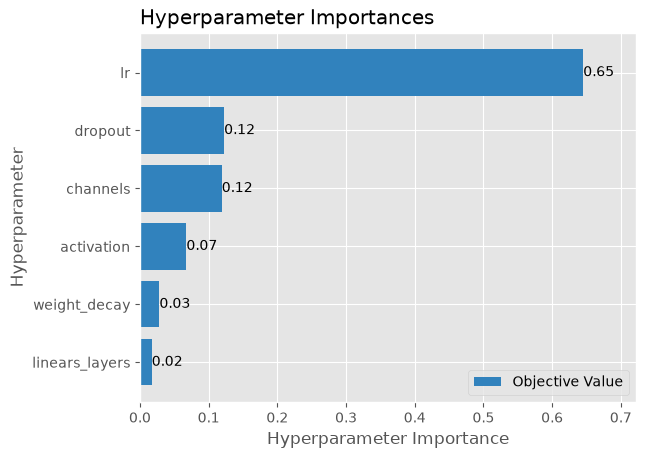

In [24]:
plot_param_importances(study)
plt.show()

### Evaluate the model using the best hyperparameters

In [25]:
model_config = {
    "input_size": SIZE,
    "channels":CHANNELS[best_params['channels']],
    "pool_size": 2,
    "dropout": best_params['dropout'],
    "linears_layers": LINEAR_LAYERS[best_params['linears_layers']],
    "activation": ACTIVATIONS[best_params['activation']],
}

summary, history, model = run_experiment(
    name="baseline_model",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=50,
    patience=6,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
)


Experiment: baseline_model
Epoch 1/50 | train loss: 2.1995 | valid loss: 2.0484 | valid ROC AUC: 0.6673
Epoch 2/50 | train loss: 1.8763 | valid loss: 1.7246 | valid ROC AUC: 0.8119
Epoch 3/50 | train loss: 1.5319 | valid loss: 1.4062 | valid ROC AUC: 0.8752
Epoch 4/50 | train loss: 1.2865 | valid loss: 1.1960 | valid ROC AUC: 0.9091
Epoch 5/50 | train loss: 1.0829 | valid loss: 1.0897 | valid ROC AUC: 0.9264
Epoch 6/50 | train loss: 0.9553 | valid loss: 1.0578 | valid ROC AUC: 0.9312
Epoch 7/50 | train loss: 0.8279 | valid loss: 1.0443 | valid ROC AUC: 0.9303
Epoch 8/50 | train loss: 0.7391 | valid loss: 0.9362 | valid ROC AUC: 0.9440
Epoch 9/50 | train loss: 0.6712 | valid loss: 1.0272 | valid ROC AUC: 0.9385
Epoch 10/50 | train loss: 0.5956 | valid loss: 1.0325 | valid ROC AUC: 0.9410
Epoch 11/50 | train loss: 0.5528 | valid loss: 1.0823 | valid ROC AUC: 0.9318
Epoch 12/50 | train loss: 0.4914 | valid loss: 1.0338 | valid ROC AUC: 0.9392
Epoch 13/50 | train loss: 0.4637 | valid loss

In [28]:
print(f"best ROC_AUC {history['best_roc']:.4f}")

best ROC_AUC 0.9440


Save model

In [27]:
torch.save(model, './models/my_Lenet_224.pth')

### Loss and ROC AUC

In [55]:
def plot_loss(history):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    axes[0].plot(history["train_loss"], label="train_loss")
    axes[0].plot(history["valid_loss"], label="valid_loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid()

    axes[1].plot(history["valid_roc"], label="valid ROC AUC")
    axes[1].set_title("Validation ROC AUC")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("ROC AUC")
    axes[1].legend()
    axes[1].grid()

    plt.tight_layout()
    plt.show()

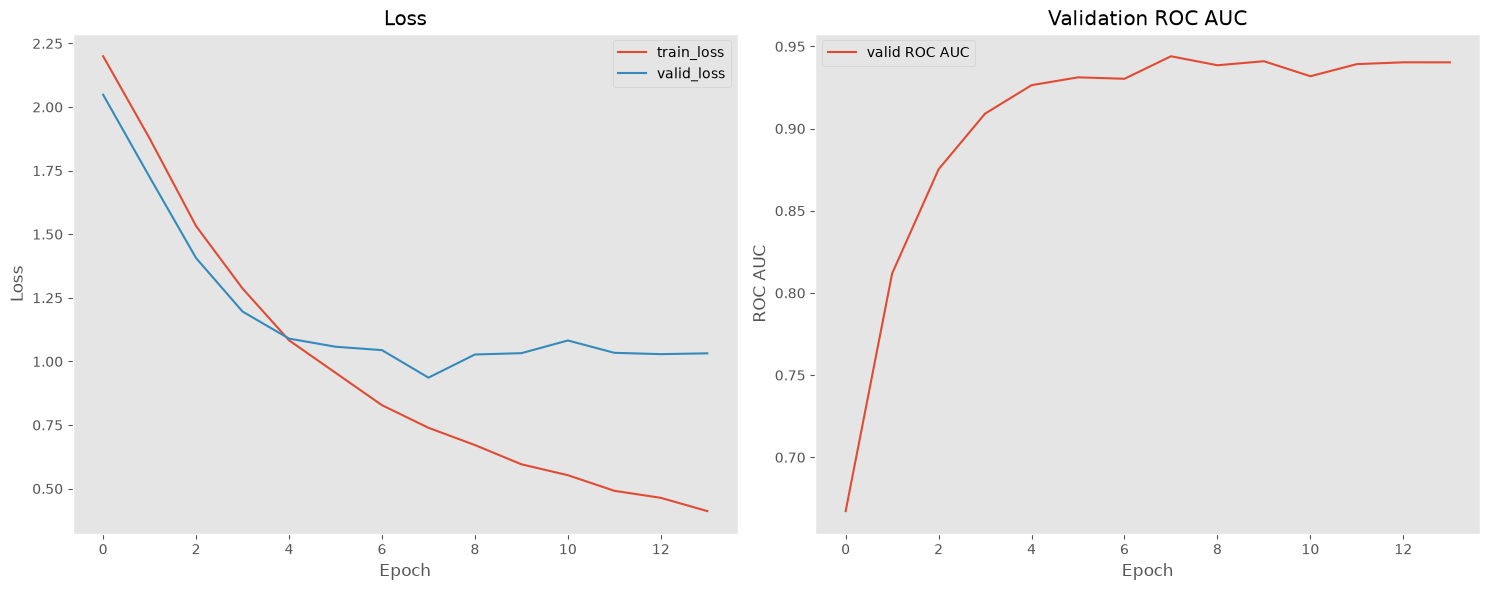

In [56]:
plot_loss(history)

### Apply different augmentations from the albumentations library and check if they improve the validation score.

##### Examples of augmentations

In [30]:
base = [
    A.SmallestMaxSize(max_size=max(SIZE)),
    A.CenterCrop(height=SIZE[0], width=SIZE[1]),
]

transforms = {
    "Original": A.Compose(base),

    "HorizontalFlip": A.Compose([
        *base,
        A.HorizontalFlip(p=1.0),
    ]),

    "Rotate": A.Compose([
        *base,
        A.Rotate(
            angle_range=(-15, 15),
            p=1.0,
        ),
    ]),

    "Affine": A.Compose([
        *base,
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.1, 0.1),
            rotate=(-15, 15),
            shear=(-5, 5),
            p=1.0,
        ),
    ]),

    "BrightnessContrast": A.Compose([
        *base,
        A.RandomBrightnessContrast(
            brightness_range=(-0.2, 0.2),
            contrast_range=(-0.2, 0.2),
            p=1.0,
        ),
    ]),

    "Combined": A.Compose([
        *base,
        A.HorizontalFlip(p=1.0),
        A.Rotate(
            angle_range=(-15, 15),
            p=1.0,
        ),
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.1, 0.1),
            rotate=(-15, 15),
            shear=(-5, 5),
            p=1.0,
        ),
        A.RandomBrightnessContrast(
            brightness_range=(-0.2, 0.2),
            contrast_range=(-0.2, 0.2),
            p=1.0,
        ),
    ]),
}

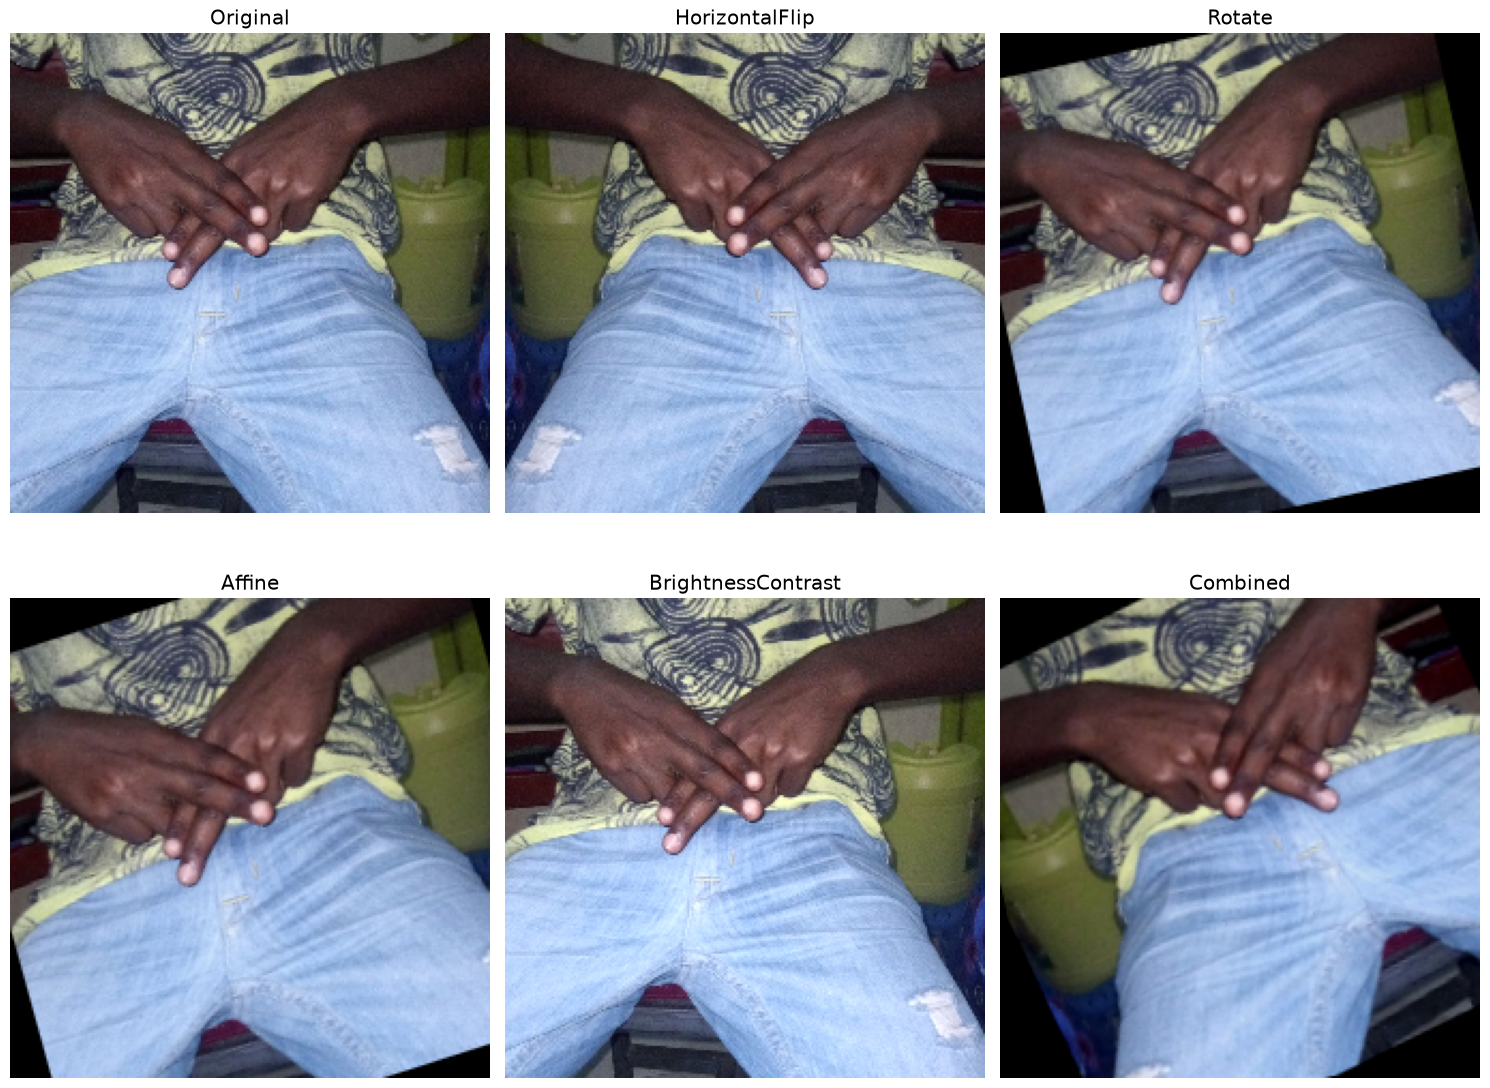

In [31]:
index_of_image = 0

image_path = (images_dir/ f"{train['img_IDS'].iloc[index_of_image]}.jpg")

image = read_image(image_path)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 12),
)

for ax, (name, transform) in zip(
    axes.flat,
    transforms.items(),
):
    result = transform(image=image)["image"]

    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Apply online augmentations

"Online" means the augmentations above are applied randomly, batch by
batch, during training (instead of once to fixed pre-saved images), by
passing them as `train_augmentations` to `make_loaders`.

Delete old tensors from GPU

In [33]:
print(f"Активно занято тензорами: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
print(f"Всего зарезервировано PyTorch: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

Активно занято тензорами: 91.39 MB
Всего зарезервировано PyTorch: 124.00 MB


In [34]:
train_loader, valid_loader = make_loaders(
    train,
    valid,
    images_dir,
    size=SIZE,
    train_augmentations=[
        A.HorizontalFlip(p=0.2),

        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.1, 0.1),
            rotate=(-15, 15),
            shear=(-5, 5),
            p=0.2,
        ),

        A.RandomBrightnessContrast(
            brightness_range=(-0.2, 0.2),
            contrast_range=(-0.2, 0.2),
            p=0.2,
        ),
    ],
)

summary_augm, history_augm, model_augm = run_experiment(
    name="model_augment",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=60,
    patience=8,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
)


Experiment: model_augment
Epoch 1/60 | train loss: 2.2374 | valid loss: 2.1896 | valid ROC AUC: 0.5461
Epoch 2/60 | train loss: 2.1339 | valid loss: 1.9430 | valid ROC AUC: 0.7254
Epoch 3/60 | train loss: 1.7245 | valid loss: 1.4244 | valid ROC AUC: 0.8720
Epoch 4/60 | train loss: 1.4089 | valid loss: 1.2603 | valid ROC AUC: 0.8993
Epoch 5/60 | train loss: 1.2504 | valid loss: 1.1402 | valid ROC AUC: 0.9177
Epoch 6/60 | train loss: 1.1695 | valid loss: 1.1284 | valid ROC AUC: 0.9197
Epoch 7/60 | train loss: 1.0852 | valid loss: 1.0574 | valid ROC AUC: 0.9311
Epoch 8/60 | train loss: 1.0228 | valid loss: 0.9999 | valid ROC AUC: 0.9354
Epoch 9/60 | train loss: 0.9562 | valid loss: 0.9571 | valid ROC AUC: 0.9421
Epoch 10/60 | train loss: 0.8907 | valid loss: 0.9802 | valid ROC AUC: 0.9403
Epoch 11/60 | train loss: 0.8899 | valid loss: 0.9301 | valid ROC AUC: 0.9442
Epoch 12/60 | train loss: 0.8179 | valid loss: 0.9008 | valid ROC AUC: 0.9492
Epoch 13/60 | train loss: 0.7827 | valid loss:

In [77]:
print(f"best ROC_AUC {history_augm['best_roc']:.4f}")

torch.save(model_augm, './models/my_Lenet_224_augmentation.pth')

best ROC_AUC 0.9631


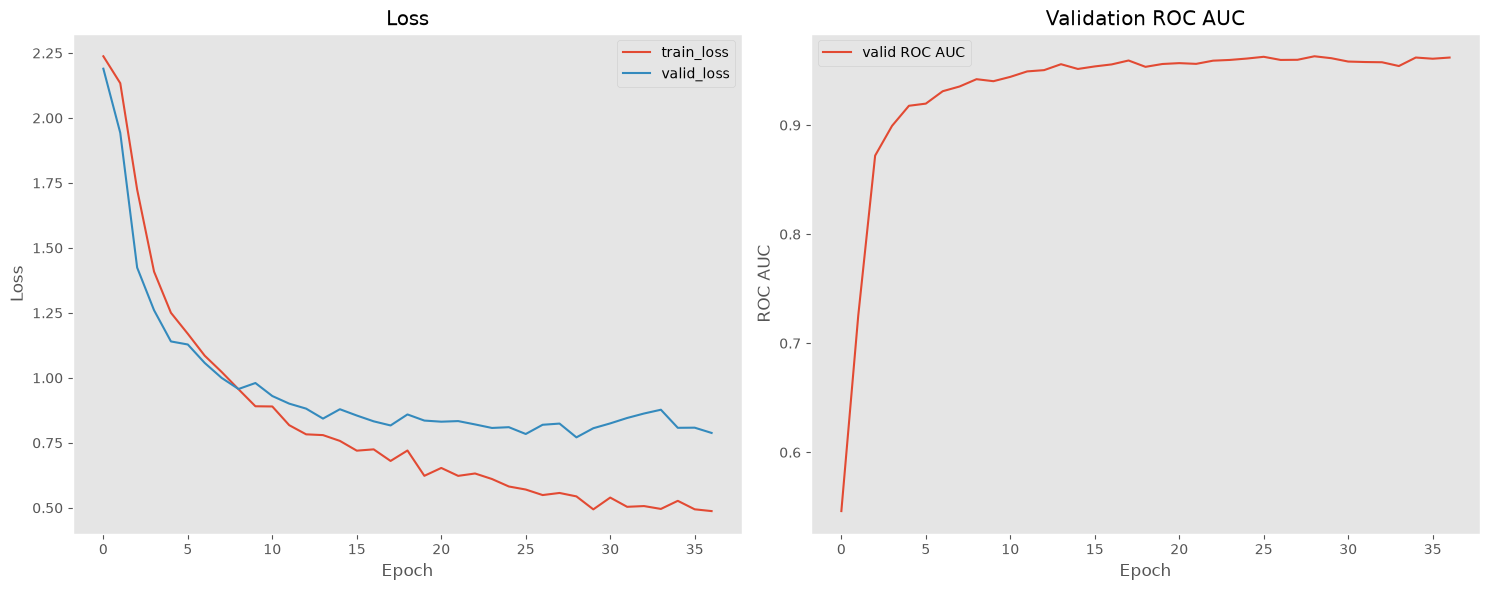

In [57]:
plot_loss(history_augm)

Applying a custom data augmentation pipeline from the Albumentations library successfully improved model performance, yielding a +0.02 boost in the validation score.

# MixUp/CutMix

Three options: MixUp only, CutMix only, or a random choice between the two for each batch.

In [36]:
mixup = v2.MixUp(
    alpha=0.2,
    num_classes=9,
)

cutmix = v2.CutMix(
    alpha=1.0,
    num_classes=9,
)

mix_both = v2.RandomChoice([
    mixup,
    cutmix,
])

In [37]:
train_loader, valid_loader = make_loaders(
    train,
    valid,
    images_dir,
    size=SIZE,
)

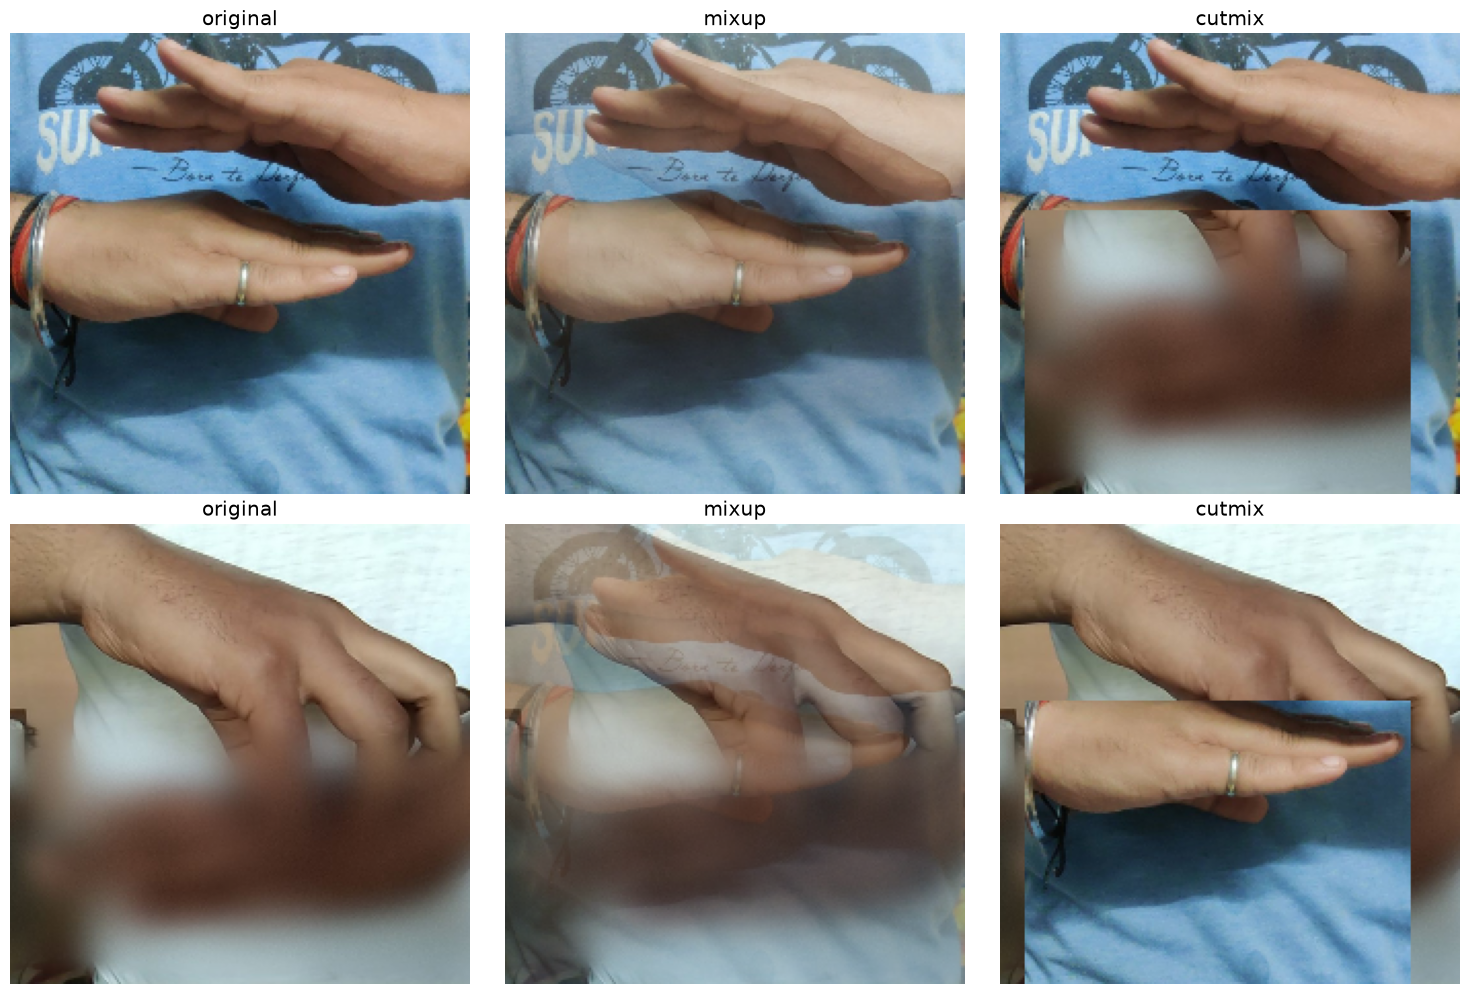

In [52]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denorm(img: torch.Tensor) -> torch.Tensor:
    img = img.cpu() * STD + MEAN
    return img.clamp(0, 1).permute(1, 2, 0)

images, targets = next(iter(train_loader))
images, targets = images[:2], targets[:2]

images_mixup, _ = mixup(images.clone(), targets.clone())
images_cutmix, _ = cutmix(images.clone(), targets.clone())

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for row in range(2):
    axes[row, 0].imshow(denorm(images[row]))
    axes[row, 0].set_title("original")

    axes[row, 1].imshow(denorm(images_mixup[row]))
    axes[row, 1].set_title("mixup")

    axes[row, 2].imshow(denorm(images_cutmix[row]))
    axes[row, 2].set_title("cutmix")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

MixUp — train with MixUp augmentation only.

In [38]:
summary_mixup, history_mixup, model_mixup = run_experiment(
    name="model_mixup",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=30,
    patience=6,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
    mix=mixup,
)


Experiment: model_mixup
Epoch 1/30 | train loss: 2.1338 | valid loss: 1.8722 | valid ROC AUC: 0.7524
Epoch 2/30 | train loss: 1.8040 | valid loss: 1.6501 | valid ROC AUC: 0.8339
Epoch 3/30 | train loss: 1.6006 | valid loss: 1.3243 | valid ROC AUC: 0.8925
Epoch 4/30 | train loss: 1.4480 | valid loss: 1.2175 | valid ROC AUC: 0.9105
Epoch 5/30 | train loss: 1.3372 | valid loss: 1.1089 | valid ROC AUC: 0.9253
Epoch 6/30 | train loss: 1.2944 | valid loss: 1.1075 | valid ROC AUC: 0.9256
Epoch 7/30 | train loss: 1.2009 | valid loss: 1.0436 | valid ROC AUC: 0.9341
Epoch 8/30 | train loss: 1.1330 | valid loss: 1.1590 | valid ROC AUC: 0.9160
Epoch 9/30 | train loss: 1.0709 | valid loss: 0.9592 | valid ROC AUC: 0.9413
Epoch 10/30 | train loss: 1.0231 | valid loss: 1.0261 | valid ROC AUC: 0.9341
Epoch 11/30 | train loss: 0.8806 | valid loss: 0.9496 | valid ROC AUC: 0.9436
Epoch 12/30 | train loss: 0.9934 | valid loss: 1.0465 | valid ROC AUC: 0.9313
Epoch 13/30 | train loss: 0.8628 | valid loss: 0

In [39]:
print(f"best ROC_AUC {history_mixup['best_roc']:.4f}")

best ROC_AUC 0.9444


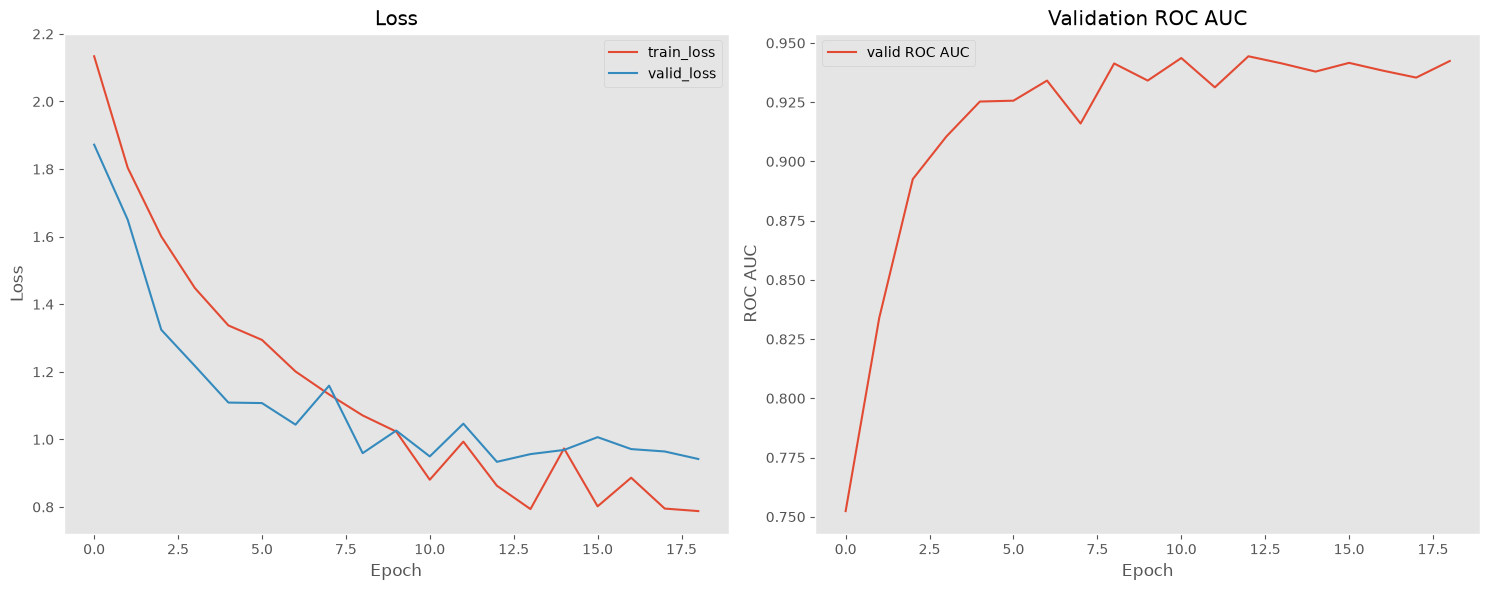

In [58]:
plot_loss(history_mixup)

CutMix — train with CutMix augmentation only.

In [40]:
summary_cutmix, history_cutmix, model_cutmix = run_experiment(
    name="model_cutmix",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=30,
    patience=6,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
    mix=cutmix,
)


Experiment: model_cutmix
Epoch 1/30 | train loss: 2.2356 | valid loss: 2.1485 | valid ROC AUC: 0.6175
Epoch 2/30 | train loss: 2.1572 | valid loss: 2.1019 | valid ROC AUC: 0.6659
Epoch 3/30 | train loss: 2.0985 | valid loss: 1.8062 | valid ROC AUC: 0.7844
Epoch 4/30 | train loss: 2.0303 | valid loss: 1.7187 | valid ROC AUC: 0.8286
Epoch 5/30 | train loss: 1.9380 | valid loss: 1.5384 | valid ROC AUC: 0.8624
Epoch 6/30 | train loss: 1.8941 | valid loss: 1.4104 | valid ROC AUC: 0.8836
Epoch 7/30 | train loss: 1.8576 | valid loss: 1.5061 | valid ROC AUC: 0.8884
Epoch 8/30 | train loss: 1.7997 | valid loss: 1.2402 | valid ROC AUC: 0.9071
Epoch 9/30 | train loss: 1.7625 | valid loss: 1.3268 | valid ROC AUC: 0.8996
Epoch 10/30 | train loss: 1.8031 | valid loss: 1.2294 | valid ROC AUC: 0.9171
Epoch 11/30 | train loss: 1.7438 | valid loss: 1.1697 | valid ROC AUC: 0.9264
Epoch 12/30 | train loss: 1.6881 | valid loss: 1.2079 | valid ROC AUC: 0.9274
Epoch 13/30 | train loss: 1.6937 | valid loss: 

In [41]:
print(f"best ROC_AUC {history_cutmix['best_roc']:.4f}")

best ROC_AUC 0.9537


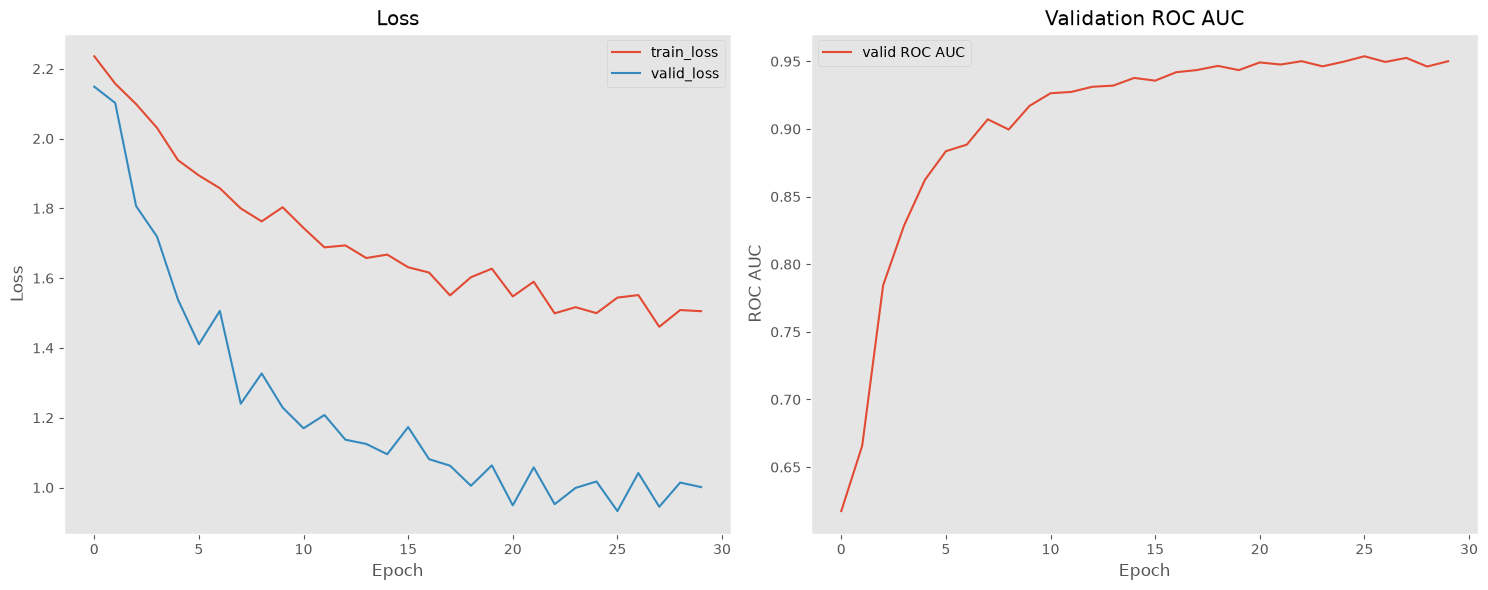

In [59]:
plot_loss(history_cutmix)

Both — MixUp and CutMix, randomly chosen per batch.

In [53]:
summary_both, history_both, model_both = run_experiment(
    name="model_both_mix",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=60,
    patience=8,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
    mix=mix_both,
)


Experiment: model_both_mix
Epoch 1/60 | train loss: 2.1981 | valid loss: 2.1285 | valid ROC AUC: 0.6397
Epoch 2/60 | train loss: 2.1370 | valid loss: 1.9599 | valid ROC AUC: 0.7295
Epoch 3/60 | train loss: 1.9712 | valid loss: 1.7475 | valid ROC AUC: 0.8204
Epoch 4/60 | train loss: 1.7776 | valid loss: 1.4242 | valid ROC AUC: 0.8720
Epoch 5/60 | train loss: 1.7092 | valid loss: 1.4088 | valid ROC AUC: 0.8903
Epoch 6/60 | train loss: 1.6121 | valid loss: 1.2400 | valid ROC AUC: 0.9107
Epoch 7/60 | train loss: 1.5541 | valid loss: 1.1703 | valid ROC AUC: 0.9216
Epoch 8/60 | train loss: 1.5623 | valid loss: 1.2617 | valid ROC AUC: 0.9145
Epoch 9/60 | train loss: 1.4770 | valid loss: 1.0805 | valid ROC AUC: 0.9290
Epoch 10/60 | train loss: 1.4568 | valid loss: 1.0624 | valid ROC AUC: 0.9360
Epoch 11/60 | train loss: 1.5221 | valid loss: 1.0705 | valid ROC AUC: 0.9331
Epoch 12/60 | train loss: 1.3963 | valid loss: 1.0045 | valid ROC AUC: 0.9394
Epoch 13/60 | train loss: 1.2805 | valid loss

In [54]:
print(f"best ROC_AUC {history_both['best_roc']:.4f}")

best ROC_AUC 0.9514


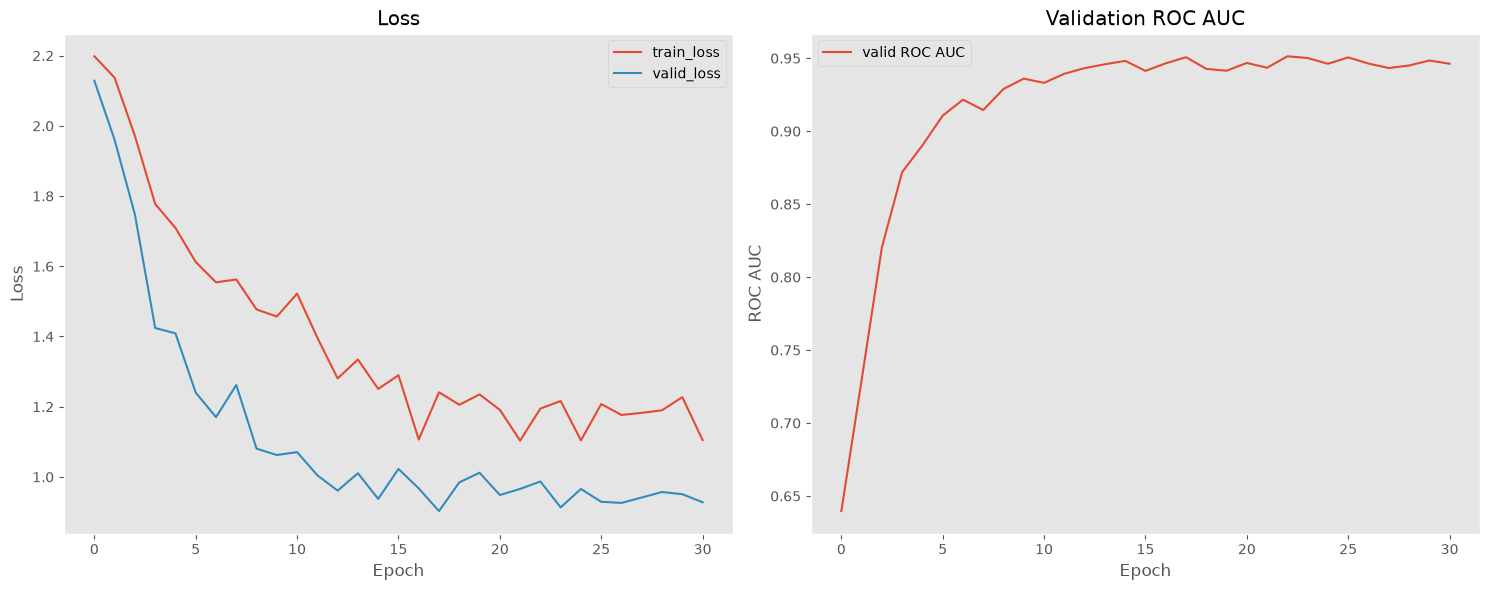

In [60]:
plot_loss(history_both)

Albumentations augmentation + MixUp + CutMix

In [61]:
train_loader, valid_loader = make_loaders(
    train,
    valid,
    images_dir,
    size=SIZE,
    train_augmentations=[
        A.HorizontalFlip(p=0.2),

        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.1, 0.1),
            rotate=(-15, 15),
            shear=(-5, 5),
            p=0.2,
        ),

        A.RandomBrightnessContrast(
            brightness_range=(-0.2, 0.2),
            contrast_range=(-0.2, 0.2),
            p=0.2,
        ),
    ],
)

summary_mixcut_augm, history_mixcut_augm, model_mixcut_augm = run_experiment(
    name="model_mixcut_augmentation",
    model_config=model_config,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    epochs=60,
    patience=10,
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    verbose=2,
    use_amp=True,
    mix=mix_both,
)


Experiment: model_mixcut_augmentation
Epoch 1/60 | train loss: 2.2013 | valid loss: 2.1969 | valid ROC AUC: 0.5284
Epoch 2/60 | train loss: 2.1854 | valid loss: 2.1567 | valid ROC AUC: 0.5924
Epoch 3/60 | train loss: 2.1631 | valid loss: 2.0622 | valid ROC AUC: 0.6978
Epoch 4/60 | train loss: 2.0956 | valid loss: 1.9425 | valid ROC AUC: 0.7542
Epoch 5/60 | train loss: 1.9478 | valid loss: 1.6512 | valid ROC AUC: 0.8398
Epoch 6/60 | train loss: 1.8844 | valid loss: 1.4421 | valid ROC AUC: 0.8669
Epoch 7/60 | train loss: 1.8785 | valid loss: 1.4220 | valid ROC AUC: 0.8794
Epoch 8/60 | train loss: 1.7915 | valid loss: 1.2847 | valid ROC AUC: 0.9018
Epoch 9/60 | train loss: 1.7203 | valid loss: 1.2473 | valid ROC AUC: 0.9105
Epoch 10/60 | train loss: 1.6618 | valid loss: 1.1815 | valid ROC AUC: 0.9187
Epoch 11/60 | train loss: 1.6203 | valid loss: 1.2395 | valid ROC AUC: 0.9186
Epoch 12/60 | train loss: 1.5984 | valid loss: 1.0947 | valid ROC AUC: 0.9327
Epoch 13/60 | train loss: 1.5181 |

In [78]:
print(f"best ROC_AUC {history_mixcut_augm['best_roc']:.4f}")

torch.save(model_mixcut_augm, './models/my_Lenet_224_augmentation_mixup_cutmix.pth')

best ROC_AUC 0.9656


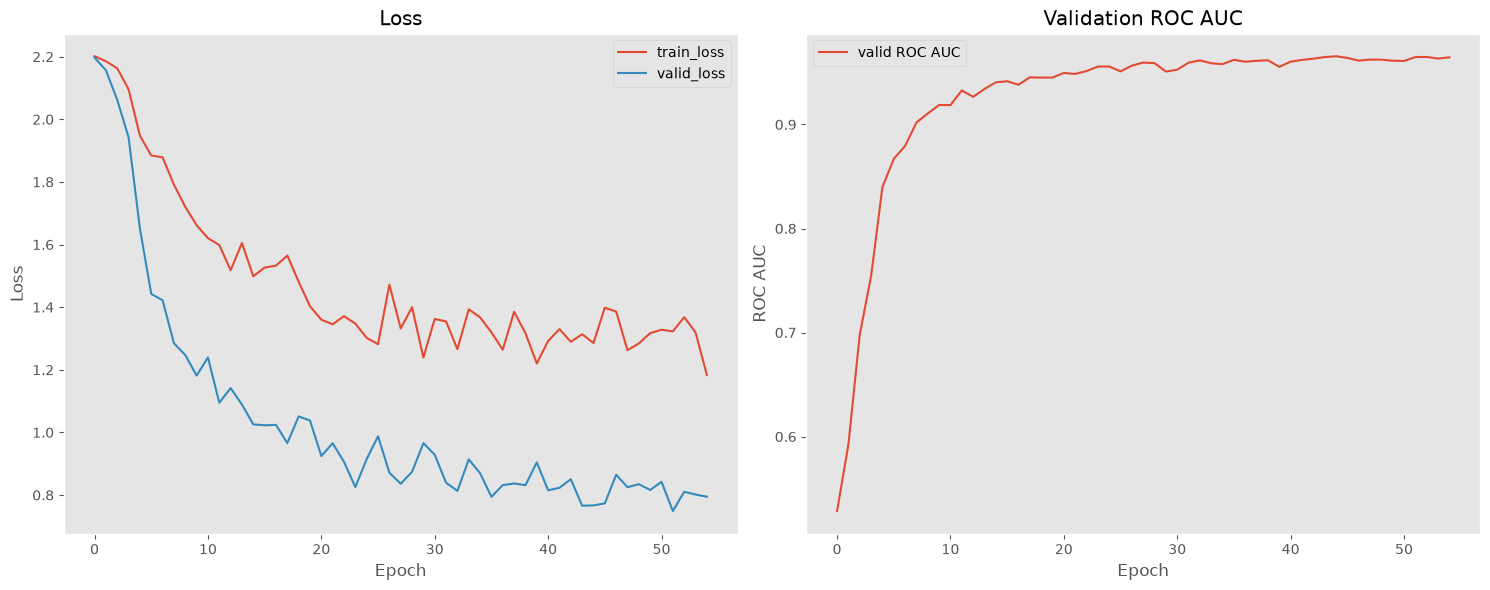

In [63]:
plot_loss(history_mixcut_augm)

## TTA validate

In [73]:
_, tta_roc = validate(
    model=model_mixcut_augm,
    valid_loader=valid_loader,
    loss_fn=nn.CrossEntropyLoss(),
    device=device,
    use_amp=True,
    tta=True,
)

In [74]:
print(f"Validation ROC AUC: {summary_mixcut_augm['best_roc']:.4f}")
print(f"TTA ROC AUC:        {tta_roc:.4f}")

Validation ROC AUC: 0.9656
TTA ROC AUC:        0.9648


# Pick resnet18 and resnet50

Change the head of your model to a linear layer with one output. Train the model for 2-4 epochs (iterations, traversals over the entire training dataset). You must be able to obtain a ROC AUC greater than 0.9. You are also advised to play with other backbones to get better results.

In [79]:
resnet18 = timm.create_model(
    "resnet18",
    pretrained=True,
    num_classes=9,
)

optimizer = torch.optim.Adam(
    resnet18.parameters(),
    lr=0.001,
    weight_decay=0.0
)

loss_fn = nn.CrossEntropyLoss()

history_resnet18 = fit(
    model=resnet18,
    train_loader=train_loader,
    valid_loader=valid_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    epochs=3,
    patience=2,
    verbose=2,
    use_amp=True,
)

Epoch 1/3 | train loss: 1.1270 | valid loss: 0.4932 | valid ROC AUC: 0.9854
Epoch 2/3 | train loss: 0.3728 | valid loss: 0.3610 | valid ROC AUC: 0.9904
Epoch 3/3 | train loss: 0.2428 | valid loss: 0.3470 | valid ROC AUC: 0.9913


In [81]:
resnet50 = timm.create_model(
    "resnet50",
    pretrained=True,
    num_classes=9,
)

optimizer = torch.optim.Adam(
    resnet50.parameters(),
    lr=0.001,
    weight_decay=0.0
)

loss_fn = nn.CrossEntropyLoss()

history_resnet50 = fit(
    model=resnet50,
    train_loader=train_loader,
    valid_loader=valid_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    epochs=3,
    patience=2,
    verbose=2,
    use_amp=True,
)

Epoch 1/3 | train loss: 1.0508 | valid loss: 0.4301 | valid ROC AUC: 0.9882
Epoch 2/3 | train loss: 0.2985 | valid loss: 0.3288 | valid ROC AUC: 0.9921
Epoch 3/3 | train loss: 0.1993 | valid loss: 0.3885 | valid ROC AUC: 0.9912


## Summary

- Built a small CNN (`my_LeNet`) and tuned its architecture and learning rate with Optuna. The baseline model tended to overfit.
- Replaced the two separate data-loading paths (one caching everything on the GPU up front, one reading from disk per epoch for augmentations) with a single `make_loaders` function, reused for every experiment below.
- Adding Albumentations augmentations (flip, affine, brightness/contrast) improved validation ROC AUC over the non-augmented baseline.
- Tried MixUp, CutMix, and a random choice between the two — none beat plain augmentation on their own, but they reduced overfitting.
- Combining Albumentations augmentation with MixUp/CutMix removed the overfitting seen in the baseline and produced the best result among the custom CNN experiments.
- Test-time augmentation (averaging predictions on the image and its horizontal flip) didn't meaningfully change the score, so it didn't help here.
- Fine-tuning pretrained `resnet18` and `resnet50` (via `timm`) — only replacing the final layer and training for a handful of epochs — clearly beat the custom CNN, becoming the overall best model.
- Overall: for this dataset, augmentation combined with MixUp/CutMix gave the strongest results among custom-trained models, but a pretrained backbone beat the small custom CNN by a wide margin even with minimal fine-tuning.